# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs('images', exist_ok=True)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv('data/AviationData_cleaned.csv')

print(f"Shape: {df.shape}")
df.info()
df.head()

C:\Users\riche\AppData\Local\Temp\ipykernel_32376\3607091862.py:1: DtypeWarning: Columns (0: Latitude, 1: Longitude) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data/AviationData_cleaned.csv')


Shape: (62663, 31)
<class 'pandas.DataFrame'>
RangeIndex: 62663 entries, 0 to 62662
Data columns (total 31 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Event.Id                62663 non-null  str    
 1   Investigation.Type      62663 non-null  str    
 2   Accident.Number         62663 non-null  str    
 3   Event.Date              62663 non-null  str    
 4   Location                62632 non-null  str    
 5   Country                 62550 non-null  str    
 6   Latitude                22574 non-null  object 
 7   Longitude               22569 non-null  object 
 8   Airport.Code            37490 non-null  str    
 9   Airport.Name            39225 non-null  str    
 10  Injury.Severity         62663 non-null  str    
 11  Aircraft.damage         60608 non-null  str    
 12  Registration.Number     61911 non-null  str    
 13  Make                    62663 non-null  str    
 14  Model                   62663 

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.People.On.Board,Serious.Fatal.Fraction,Destroyed,Make_Model
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,1.0,3.0,VMC,Approach,Probable Cause,NaN,4.0,0.0,0.0,Cessna 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,Cessna 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,0.0,1.0,VMC,Takeoff,Probable Cause,NaN,1.0,0.0,0.0,Cessna 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,2.0,0.0,VMC,Approach,Probable Cause,NaN,2.0,0.0,0.0,Piper PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,Cessna 140


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# Separate small and large aircraft using 20-passenger threshold
df_small = df[df['Total.People.On.Board'] <= 20].copy()
df_large = df[df['Total.People.On.Board'] > 20].copy()

print(f"Small aircraft (≤20 pax): {df_small.shape[0]} records")
print(f"Large aircraft (>20 pax): {df_large.shape[0]} records")
print(f"\nSmall aircraft - unique makes: {df_small['Make'].nunique()}")
print(f"Large aircraft - unique makes: {df_large['Make'].nunique()}")

Small aircraft (≤20 pax): 60132 records
Large aircraft (>20 pax): 2531 records

Small aircraft - unique makes: 76
Large aircraft - unique makes: 23


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

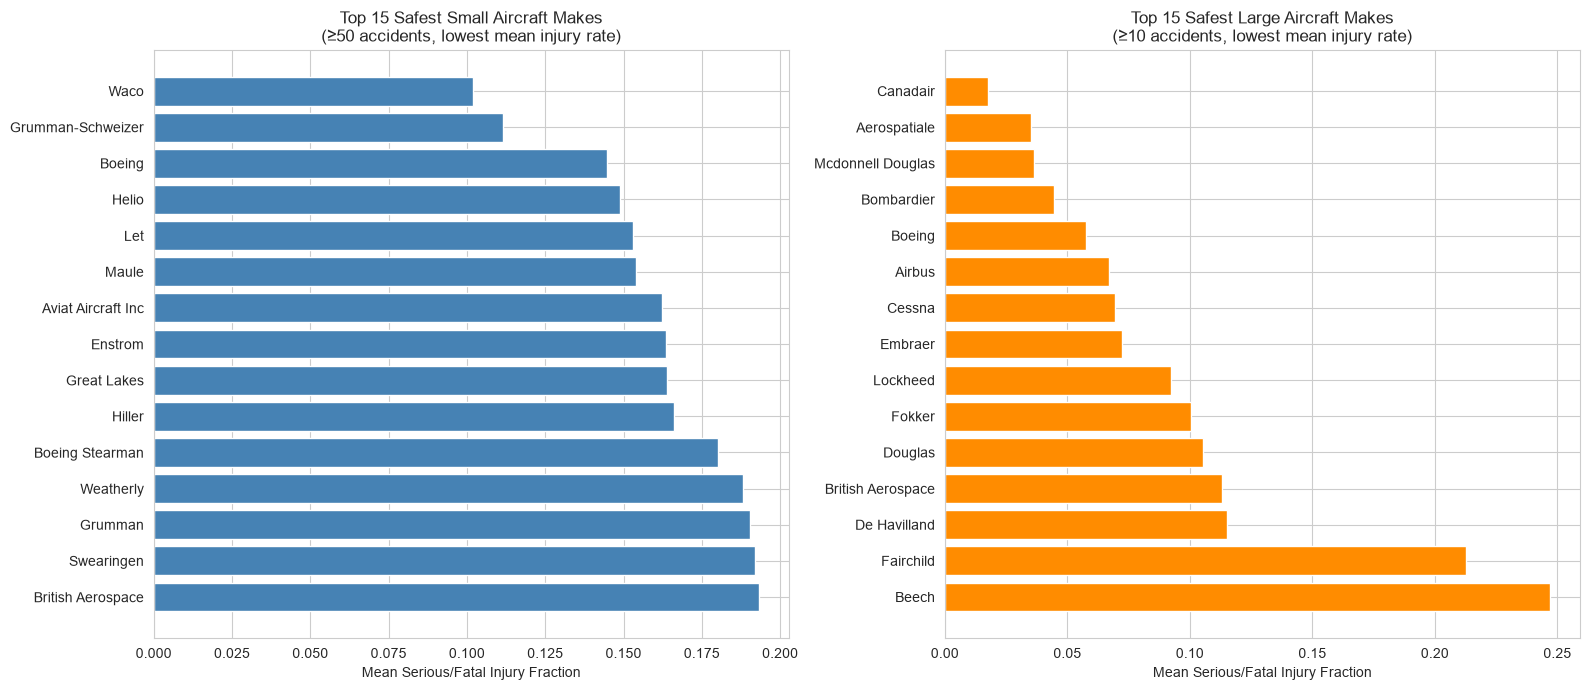

Small aircraft — 15 lowest injury makes (with sample size):


,mean,count
Make,,
Waco,0.101918,139
Grumman-Schweizer,0.111549,127
Boeing,0.144626,686
Helio,0.148728,106
Let,0.153061,98
Maule,0.153889,570
Aviat Aircraft Inc,0.162338,77
Enstrom,0.163522,212
Great Lakes,0.163793,58



Large aircraft — 15 lowest injury makes (with sample size):


,mean,count
Make,,
Canadair,0.017705,21
Aerospatiale,0.035119,34
Mcdonnell Douglas,0.036424,329
Bombardier,0.044372,83
Boeing,0.057586,1391
Airbus,0.066849,267
Cessna,0.069383,15
Embraer,0.072220,111
Lockheed,0.092159,38


In [4]:
# Mean serious/fatal fraction by make — with sample size control
# Small aircraft: require ≥50 accidents per make (same threshold as cleaning)
small_make_stats = (df_small.groupby('Make')['Serious.Fatal.Fraction']
                    .agg(['mean', 'count']))
small_make_stats = small_make_stats[small_make_stats['count'] >= 50]
small_make_stats = small_make_stats.sort_values('mean')
top15_small = small_make_stats.head(15)

# Large aircraft: require ≥10 accidents per make (fewer large-aircraft
# accidents exist overall, so a lower threshold is appropriate; this still
# gives enough data points for a reliable average)
large_make_stats = (df_large.groupby('Make')['Serious.Fatal.Fraction']
                    .agg(['mean', 'count']))
large_make_stats = large_make_stats[large_make_stats['count'] >= 10]
large_make_stats = large_make_stats.sort_values('mean')
top15_large = large_make_stats.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].barh(top15_small.index, top15_small['mean'], color='steelblue')
axes[0].set_xlabel('Mean Serious/Fatal Injury Fraction')
axes[0].set_title('Top 15 Safest Small Aircraft Makes\n(≥50 accidents, lowest mean injury rate)')
axes[0].invert_yaxis()

axes[1].barh(top15_large.index, top15_large['mean'], color='darkorange')
axes[1].set_xlabel('Mean Serious/Fatal Injury Fraction')
axes[1].set_title('Top 15 Safest Large Aircraft Makes\n(≥10 accidents, lowest mean injury rate)')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig('images/top15_makes_injury_rate.png', dpi=150, bbox_inches='tight')
plt.show()

print("Small aircraft — 15 lowest injury makes (with sample size):")
display(top15_small)
print("\nLarge aircraft — 15 lowest injury makes (with sample size):")
display(top15_large)

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

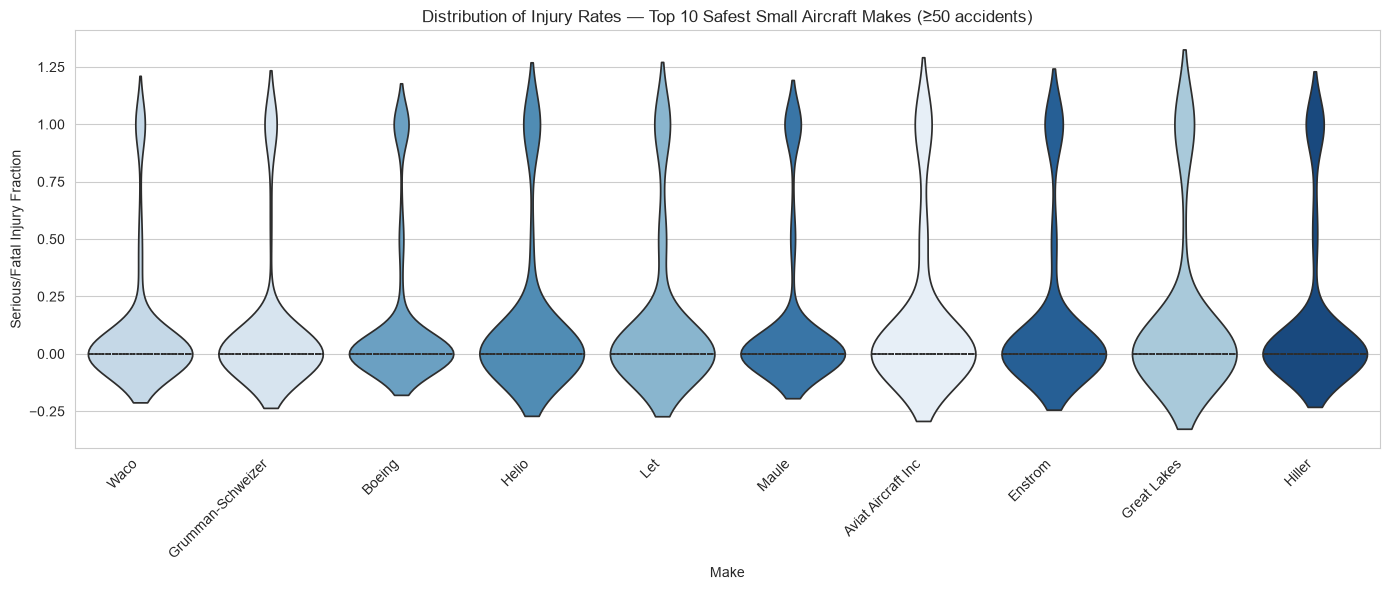

In [5]:
# Top 10 safest small makes (from the sample-size-filtered stats above)
top10_small_names = top15_small.head(10).index.tolist()
df_small_top10 = df_small[df_small['Make'].isin(top10_small_names)]

plt.figure(figsize=(14, 6))
order = (df_small_top10.groupby('Make')['Serious.Fatal.Fraction']
         .mean().sort_values().index)
sns.violinplot(data=df_small_top10, x='Make', y='Serious.Fatal.Fraction',
               hue='Make', order=order, palette='Blues_r', inner='quartile',
               legend=False)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Make')
plt.ylabel('Serious/Fatal Injury Fraction')
plt.title('Distribution of Injury Rates — Top 10 Safest Small Aircraft Makes (≥50 accidents)')
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

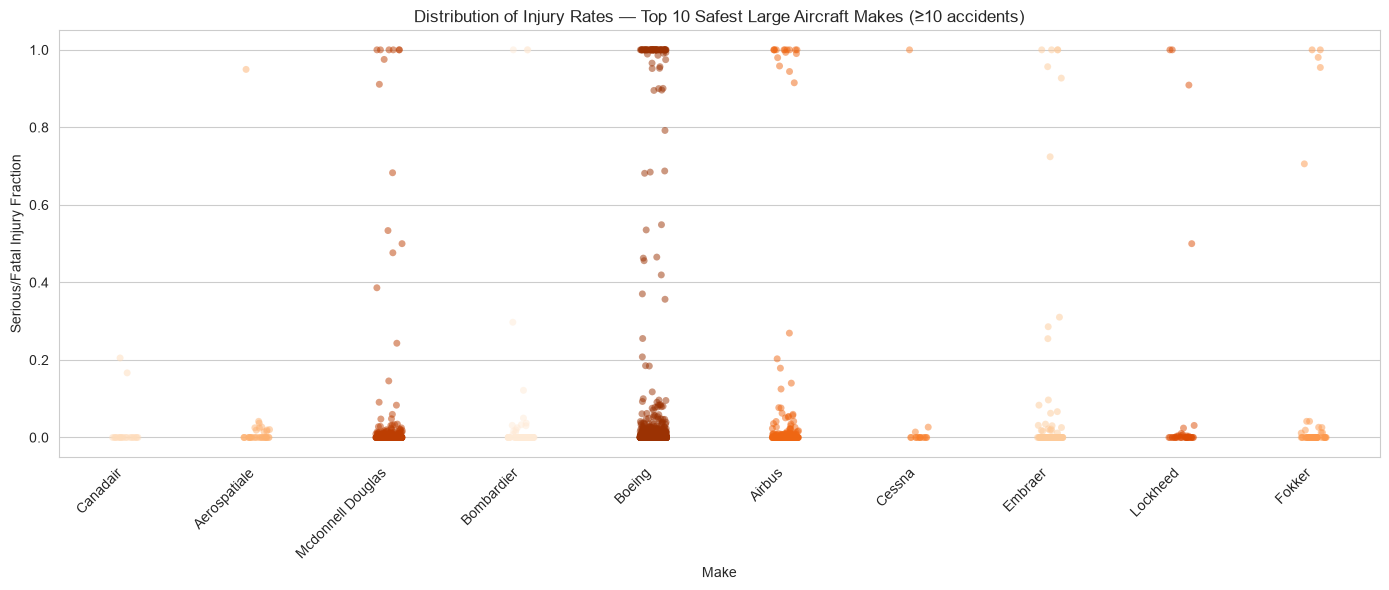

In [6]:
# Top 10 safest large makes (from the sample-size-filtered stats above)
top10_large_names = top15_large.head(10).index.tolist()
df_large_top10 = df_large[df_large['Make'].isin(top10_large_names)]

plt.figure(figsize=(14, 6))
order = (df_large_top10.groupby('Make')['Serious.Fatal.Fraction']
         .mean().sort_values().index)
sns.stripplot(data=df_large_top10, x='Make', y='Serious.Fatal.Fraction',
              hue='Make', order=order, palette='Oranges_r', jitter=True,
              alpha=0.5, legend=False)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Make')
plt.ylabel('Serious/Fatal Injury Fraction')
plt.title('Distribution of Injury Rates — Top 10 Safest Large Aircraft Makes (≥10 accidents)')
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

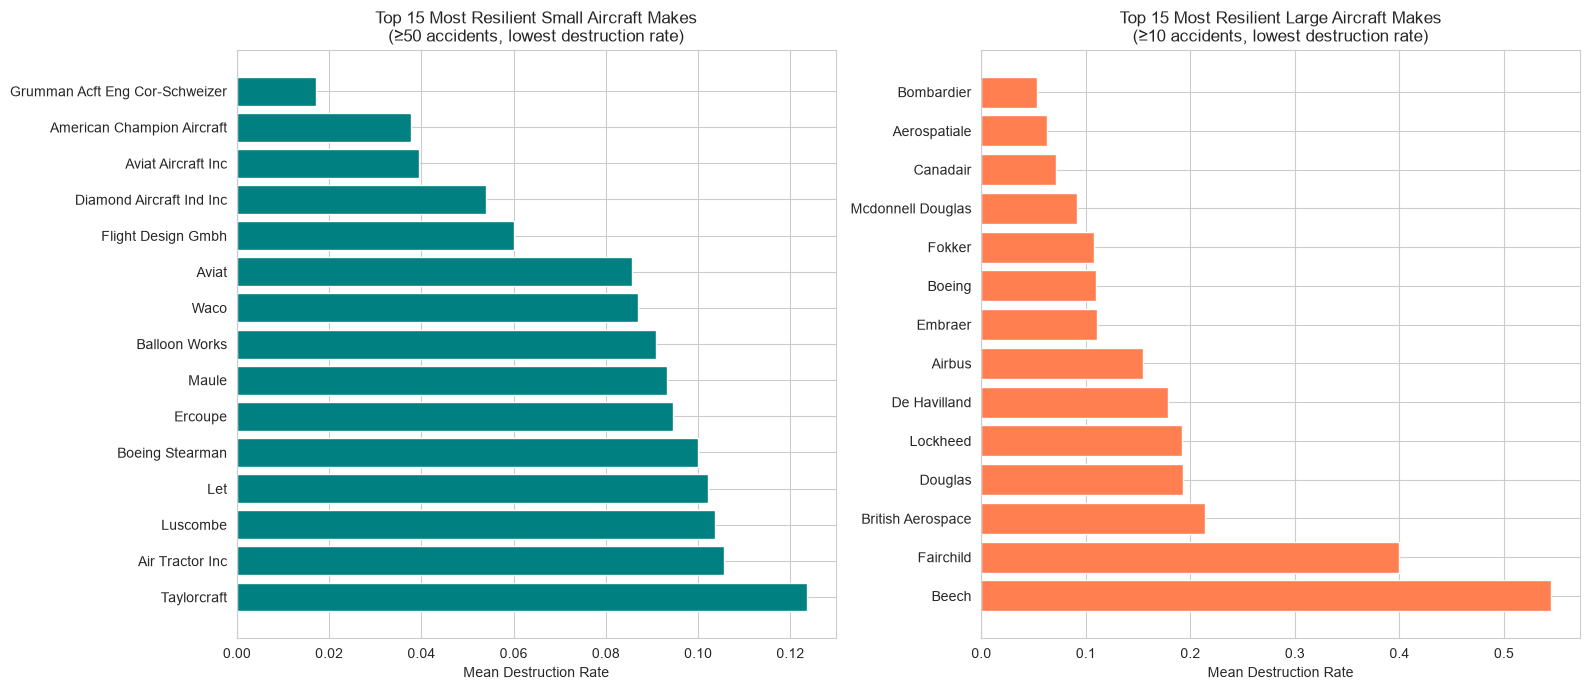

Small aircraft — 15 lowest destruction rates (with sample size):


,mean,count
Make,,
Grumman Acft Eng Cor-Schweizer,0.017241,58
American Champion Aircraft,0.037736,53
Aviat Aircraft Inc,0.039474,76
Diamond Aircraft Ind Inc,0.054054,74
Flight Design Gmbh,0.060000,50
Aviat,0.085714,140
Waco,0.086957,138
Balloon Works,0.090909,77
Maule,0.093146,569



Large aircraft — 15 lowest destruction rates (with sample size):


,mean,count
Make,,
Bombardier,0.053571,56
Aerospatiale,0.062500,16
Canadair,0.071429,14
Mcdonnell Douglas,0.091346,208
Fokker,0.108108,37
Boeing,0.109739,729
Embraer,0.111111,63
Airbus,0.154472,123
De Havilland,0.178571,28


In [7]:
# Destruction rate by make — with sample size control
small_dest_stats = (df_small.groupby('Make')['Destroyed']
                    .agg(['mean', 'count']))
small_dest_stats = small_dest_stats[small_dest_stats['count'] >= 50]
small_dest_stats = small_dest_stats.sort_values('mean')
top15_small_dest = small_dest_stats.head(15)

large_dest_stats = (df_large.groupby('Make')['Destroyed']
                    .agg(['mean', 'count']))
large_dest_stats = large_dest_stats[large_dest_stats['count'] >= 10]
large_dest_stats = large_dest_stats.sort_values('mean')
top15_large_dest = large_dest_stats.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].barh(top15_small_dest.index, top15_small_dest['mean'], color='teal')
axes[0].set_xlabel('Mean Destruction Rate')
axes[0].set_title('Top 15 Most Resilient Small Aircraft Makes\n(≥50 accidents, lowest destruction rate)')
axes[0].invert_yaxis()

axes[1].barh(top15_large_dest.index, top15_large_dest['mean'], color='coral')
axes[1].set_xlabel('Mean Destruction Rate')
axes[1].set_title('Top 15 Most Resilient Large Aircraft Makes\n(≥10 accidents, lowest destruction rate)')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig('images/top15_makes_destruction_rate.png', dpi=150, bbox_inches='tight')
plt.show()

print("Small aircraft — 15 lowest destruction rates (with sample size):")
display(top15_small_dest)
print("\nLarge aircraft — 15 lowest destruction rates (with sample size):")
display(top15_large_dest)

**Cross-referencing injury and destruction rankings**

Makes that appear in *both* the Top 15 lowest injury fraction and the Top 15 lowest destruction rate are the strongest recommendations, since they perform well on both metrics simultaneously.

In [8]:
# Cross-reference: makes present in BOTH the injury and destruction top-15
small_injury_top15 = set(top15_small.index)
small_dest_top15 = set(top15_small_dest.index)
small_both = sorted(small_injury_top15 & small_dest_top15)

large_injury_top15 = set(top15_large.index)
large_dest_top15 = set(top15_large_dest.index)
large_both = sorted(large_injury_top15 & large_dest_top15)

print("Small-aircraft makes in BOTH Top 15 (injury + destruction):")
for m in small_both:
    inj = top15_small.loc[m, 'mean']
    dest = top15_small_dest.loc[m, 'mean']
    n_inj = top15_small.loc[m, 'count']
    print(f"  {m:30s}  injury={inj:.3f} (n={int(n_inj)}), destruction={dest:.3f}")

print(f"\nLarge-aircraft makes in BOTH Top 15 (injury + destruction):")
for m in large_both:
    inj = top15_large.loc[m, 'mean']
    dest = top15_large_dest.loc[m, 'mean']
    n_inj = top15_large.loc[m, 'count']
    print(f"  {m:30s}  injury={inj:.3f} (n={int(n_inj)}), destruction={dest:.3f}")

Small-aircraft makes in BOTH Top 15 (injury + destruction):
  Aviat Aircraft Inc              injury=0.162 (n=77), destruction=0.039
  Boeing Stearman                 injury=0.180 (n=50), destruction=0.100
  Let                             injury=0.153 (n=98), destruction=0.102
  Maule                           injury=0.154 (n=570), destruction=0.093
  Waco                            injury=0.102 (n=139), destruction=0.087

Large-aircraft makes in BOTH Top 15 (injury + destruction):
  Aerospatiale                    injury=0.035 (n=34), destruction=0.062
  Airbus                          injury=0.067 (n=267), destruction=0.154
  Beech                           injury=0.247 (n=14), destruction=0.545
  Boeing                          injury=0.058 (n=1391), destruction=0.110
  Bombardier                      injury=0.044 (n=83), destruction=0.054
  British Aerospace               injury=0.113 (n=27), destruction=0.214
  Canadair                        injury=0.018 (n=21), destruction=0.07

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Discussion — Make-Level Findings

**Small aircraft (≥50 accidents per make):**  
The five makes that appear in both the injury and destruction Top 15 are **Waco** (mean injury 0.10, n=139), **Maule** (0.15, n=570), **Let** (0.15, n=98), **Aviat Aircraft Inc** (0.16, n=77), and **Boeing Stearman** (0.18, n=50). These combine the lowest mean serious/fatal injury fractions with the lowest destruction rates, backed by sample sizes ranging from 50 to 570 accidents.

The violin plots show that for most of these makes, the bulk of data points sit at 0 (no serious/fatal injuries), but the tails extend toward 1.0 — a pattern typical of general aviation, where outcomes are bimodal (most accidents are minor, but some are catastrophic). **Waco** and **Maule** stand out with the best combination of low mean and reasonably large samples.

**Large aircraft (≥10 accidents per make):**  
Nearly all qualifying large-aircraft makes appear in both Top 15 lists, since the pool is smaller. The top performers are **Canadair** (mean injury 0.02, n=21), **Aerospatiale** (0.04, n=34), **Mcdonnell Douglas** (0.04, n=329), **Bombardier** (0.04, n=83), and **Boeing** (0.06, n=1391). Boeing's sample of 1,391 large-aircraft accidents makes it by far the most statistically robust result.

The strip plot confirms that for Boeing, Mcdonnell Douglas, Bombardier, and Airbus, the overwhelming majority of data points cluster near zero, with only rare high-severity outliers.

**Recommendations:**  
- *Small aircraft:* **Waco**, **Maule**, and **Let** are the strongest picks (low injury, low destruction, adequate sample sizes).  
- *Large aircraft:* **Bombardier**, **Mcdonnell Douglas**, and **Boeing** offer the best insuring profile — Bombardier has the lowest destruction rate (0.05), Mcdonnell Douglas the lowest injury fraction (0.04) among high-count makes, and Boeing provides the deepest evidence base (n=1,391).

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

Large plane types with ≥10 accidents: 57


,mean,count
Make_Model,,
Mcdonnell Douglas MD-83,0.001137,18
Mcdonnell Douglas MD-80,0.001200,15
Boeing 717-200,0.001350,15
Boeing 737-322,0.001444,12
Boeing 757-251,0.001463,10
Boeing 747-422,0.002208,12
Boeing 737-7H4,0.002721,17
Boeing 737-3H4,0.002832,10
Boeing 787,0.003058,11


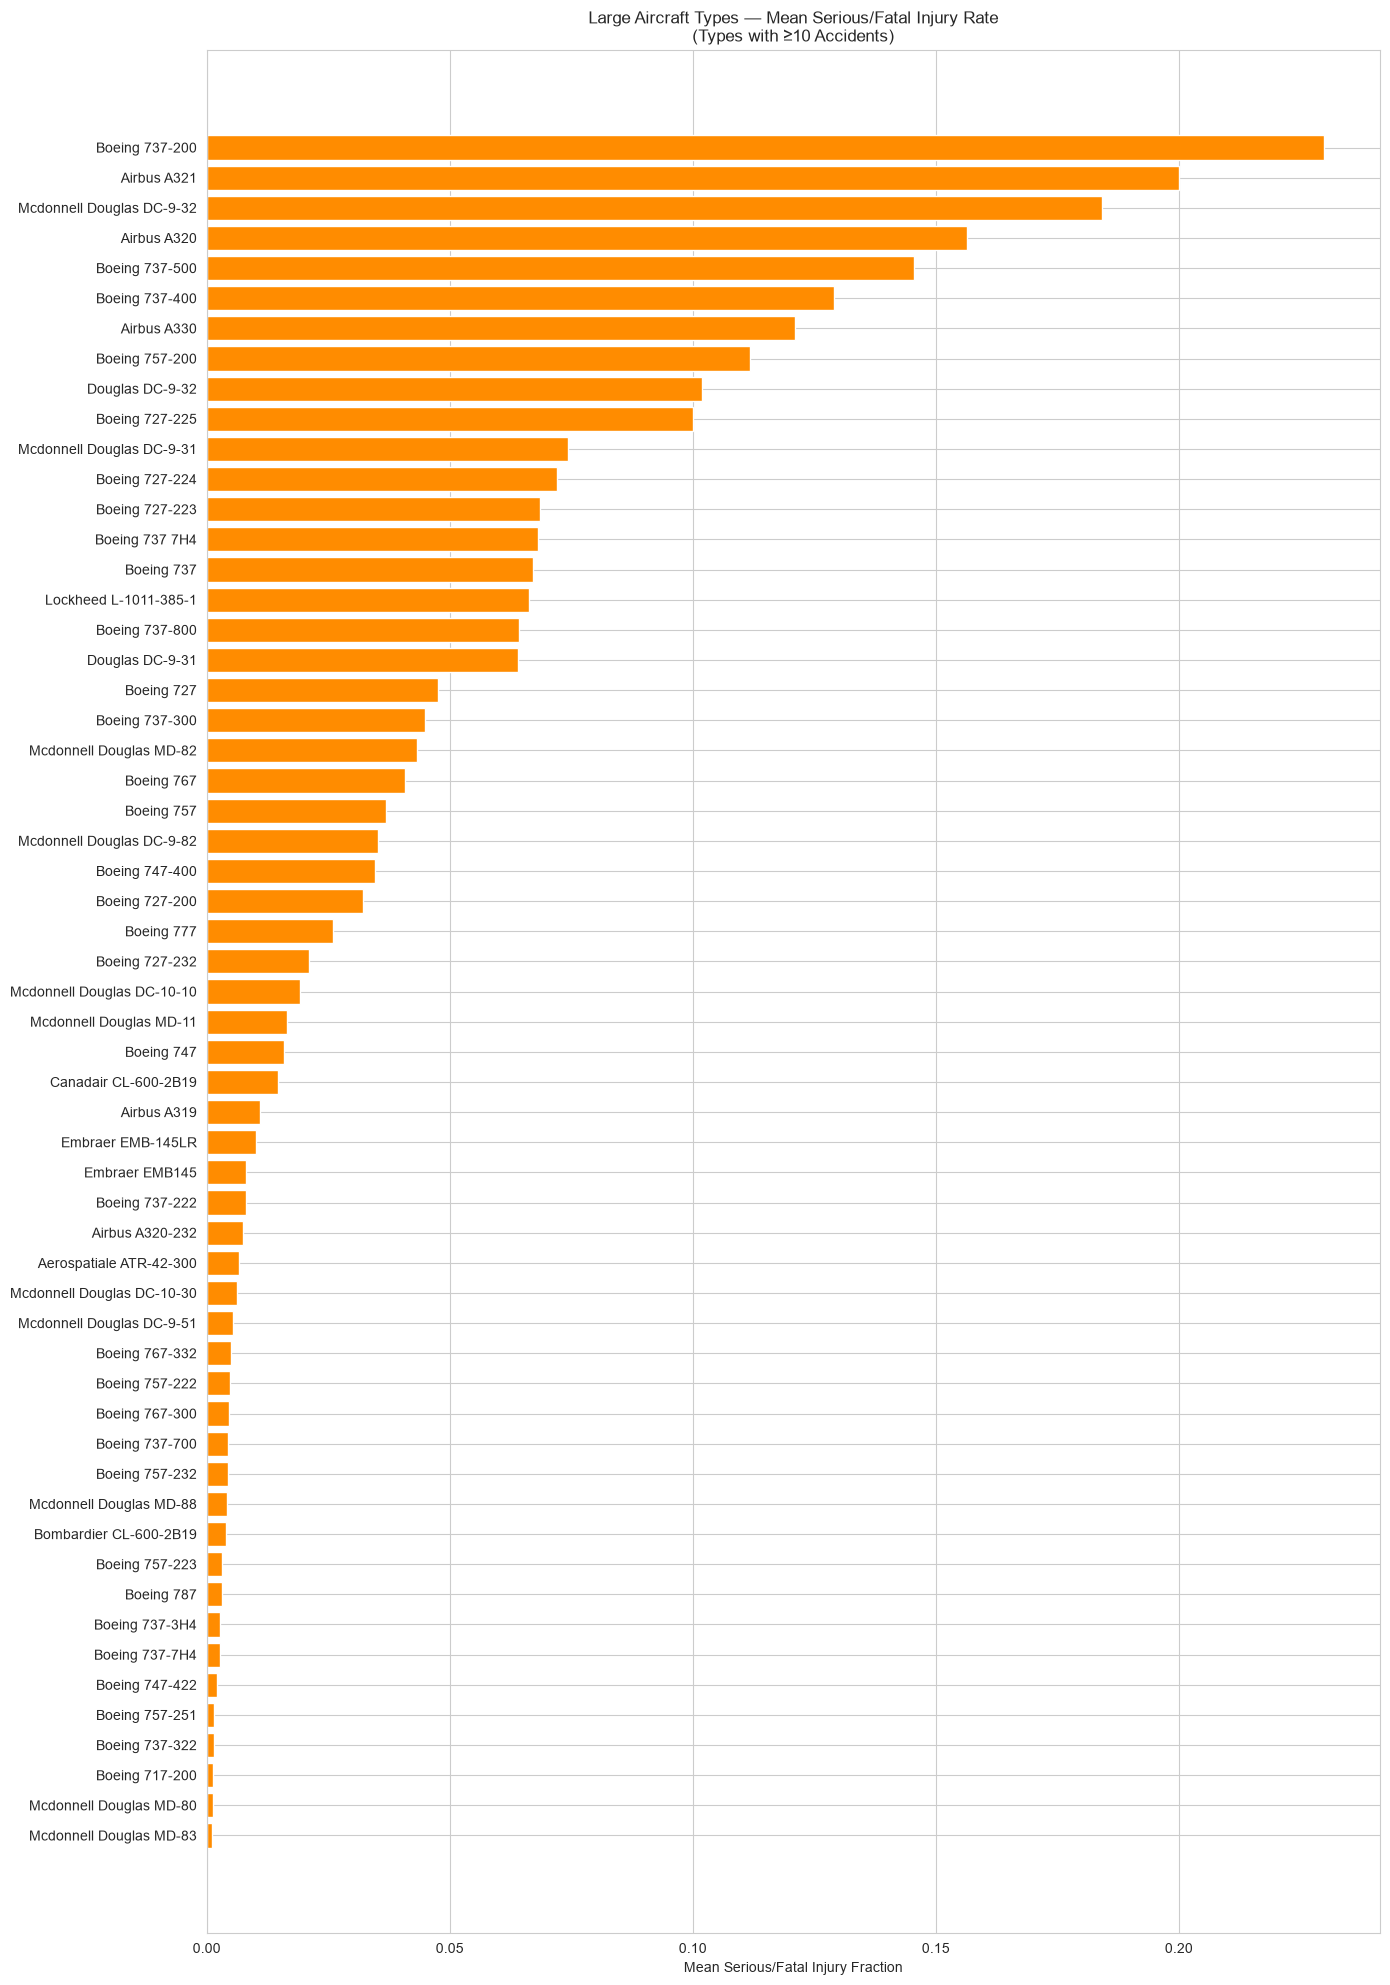

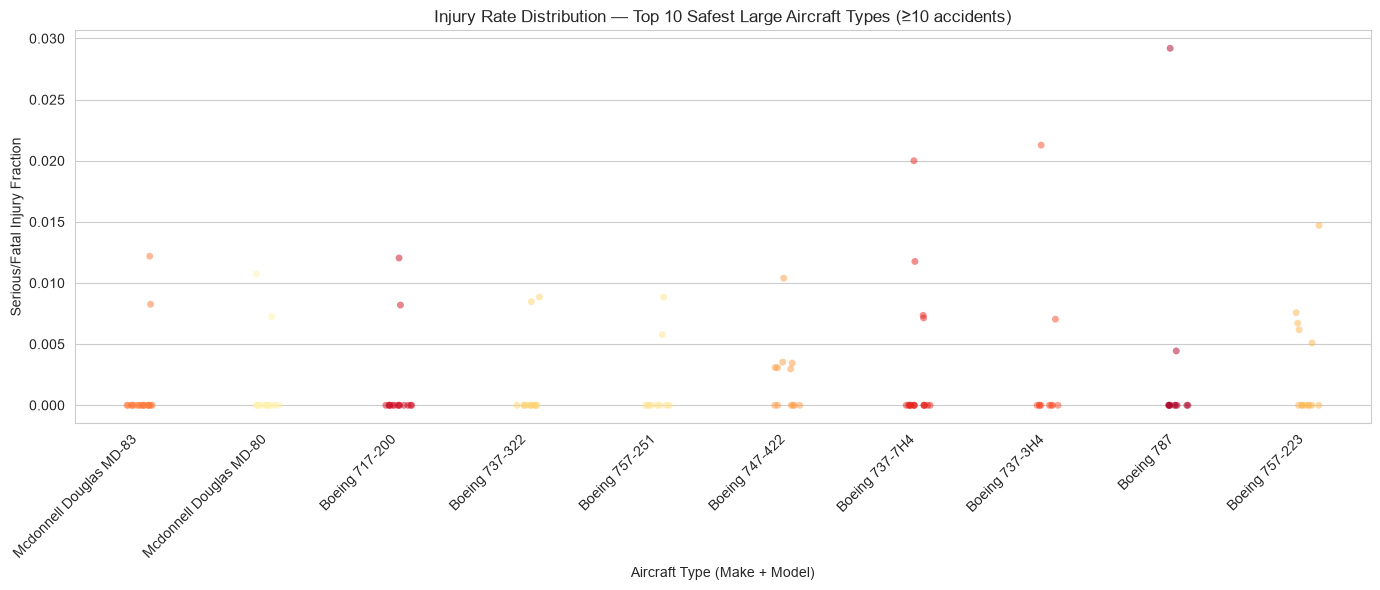

In [9]:
# Large planes: filter Make_Model with at least 10 accidents
large_type_counts = df_large['Make_Model'].value_counts()
valid_large_types = large_type_counts[large_type_counts >= 10].index
df_large_types = df_large[df_large['Make_Model'].isin(valid_large_types)]

large_type_stats = (df_large_types.groupby('Make_Model')['Serious.Fatal.Fraction']
                    .agg(['mean', 'count']).sort_values('mean'))

print(f"Large plane types with ≥10 accidents: {len(valid_large_types)}")
display(large_type_stats)

# Bar chart of mean injury fraction
plt.figure(figsize=(14, max(6, len(large_type_stats) * 0.35)))
plt.barh(large_type_stats.index, large_type_stats['mean'], color='darkorange')
plt.xlabel('Mean Serious/Fatal Injury Fraction')
plt.title('Large Aircraft Types — Mean Serious/Fatal Injury Rate\n(Types with ≥10 Accidents)')
plt.tight_layout()
plt.show()

# Distribution plot (strip plot) for top 10
top_large_types = large_type_stats.head(10).index.tolist()
df_plot = df_large_types[df_large_types['Make_Model'].isin(top_large_types)]
order = (df_plot.groupby('Make_Model')['Serious.Fatal.Fraction']
         .mean().sort_values().index)

plt.figure(figsize=(14, 6))
sns.stripplot(data=df_plot, x='Make_Model', y='Serious.Fatal.Fraction',
              hue='Make_Model', order=order, palette='YlOrRd', jitter=True,
              alpha=0.5, legend=False)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Aircraft Type (Make + Model)')
plt.ylabel('Serious/Fatal Injury Fraction')
plt.title('Injury Rate Distribution — Top 10 Safest Large Aircraft Types (≥10 accidents)')
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

Small plane types with ≥10 accidents: 772


,mean,count
Make_Model,,
Piper PA-18A 150,0.000000,12
Mcdonnell Douglas MD-11F,0.000000,10
Grumman G164B,0.000000,16
Cessna 180C,0.000000,15
Diamond Aircraft Ind Inc DA 20 C1,0.000000,11
Maule MX-7-235,0.029412,17
Burkhart Grob G103,0.033333,15
Air Tractor AT 602,0.038462,13
Cessna 560XL,0.040000,25


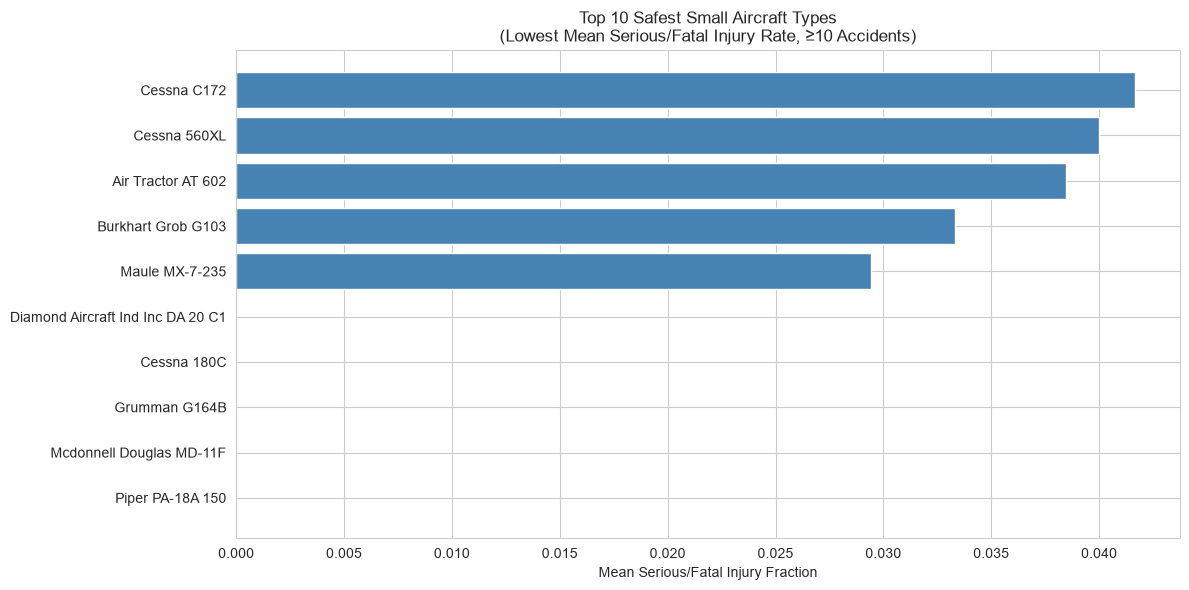

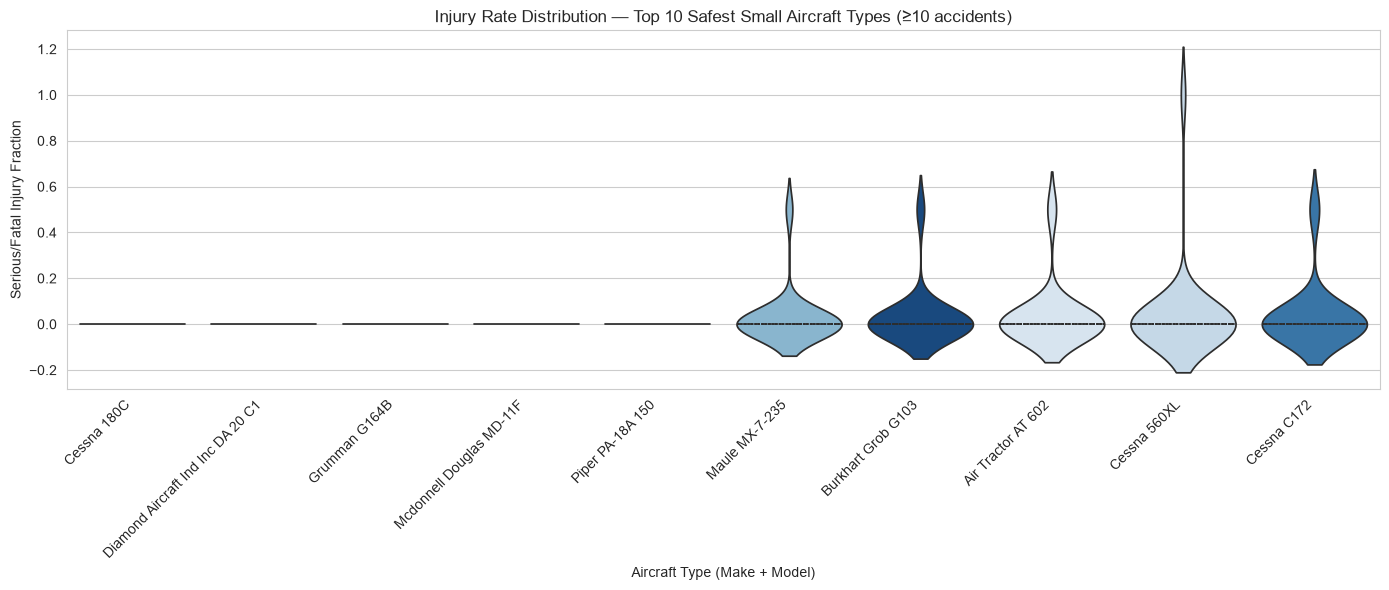

In [10]:
# Small planes: filter Make_Model with at least 10 accidents
small_type_counts = df_small['Make_Model'].value_counts()
valid_small_types = small_type_counts[small_type_counts >= 10].index
df_small_types = df_small[df_small['Make_Model'].isin(valid_small_types)]

small_type_stats = (df_small_types.groupby('Make_Model')['Serious.Fatal.Fraction']
                    .agg(['mean', 'count']).sort_values('mean'))

print(f"Small plane types with ≥10 accidents: {len(valid_small_types)}")

# Top 10 lowest injury fraction
top10_small_types = small_type_stats.head(10)
display(top10_small_types)

# Bar chart
plt.figure(figsize=(12, 6))
plt.barh(top10_small_types.index, top10_small_types['mean'], color='steelblue')
plt.xlabel('Mean Serious/Fatal Injury Fraction')
plt.title('Top 10 Safest Small Aircraft Types\n(Lowest Mean Serious/Fatal Injury Rate, ≥10 Accidents)')
plt.tight_layout()
plt.show()

# Violin plot for top 10
df_plot_small = df_small_types[df_small_types['Make_Model'].isin(top10_small_types.index)]
order = (df_plot_small.groupby('Make_Model')['Serious.Fatal.Fraction']
         .mean().sort_values().index)

plt.figure(figsize=(14, 6))
sns.violinplot(data=df_plot_small, x='Make_Model', y='Serious.Fatal.Fraction',
               hue='Make_Model', order=order, palette='Blues_r', inner='quartile',
               legend=False)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Aircraft Type (Make + Model)')
plt.ylabel('Serious/Fatal Injury Fraction')
plt.title('Injury Rate Distribution — Top 10 Safest Small Aircraft Types (≥10 accidents)')
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion — Aircraft Type Findings

**Large aircraft types (≥10 accidents per Make + Model):**  
The safest large-aircraft types are dominated by narrow-body jets from Mcdonnell Douglas and Boeing. The top five are **Mcdonnell Douglas MD-83** (mean injury 0.001, n=18), **Mcdonnell Douglas MD-80** (0.001, n=15), **Boeing 717-200** (0.001, n=15), **Boeing 737-322** (0.001, n=12), and **Boeing 757-251** (0.001, n=10). These types have near-zero average injury fractions across a sufficient number of incidents. The strip plot confirms that virtually all data points sit at 0, with catastrophic outcomes being extremely rare.

At the other end, older types like the **Boeing 737-200** (0.23, n=39) and **Airbus A321** (0.20, n=10) show higher averages, reflecting earlier-generation designs or smaller samples.

**Small aircraft types (≥10 accidents per Make + Model):**  
Several small-aircraft types achieved a perfect 0.00 mean injury fraction: **Piper PA-18A 150** (n=12), **Grumman G164B** (n=16), **Cessna 180C** (n=15), and **Diamond DA 20 C1** (n=11). While perfect records are partly a function of small samples, they still represent at least 10 accidents each. The next tier includes **Maule MX-7-235** (0.03, n=17) and **Burkhart Grob G103** (0.03, n=15).

**Recommendations:**  
- *Large aircraft:* The client should favor the **Mcdonnell Douglas MD-80/MD-83** family and **Boeing 717/737/757** variants, which combine the lowest injury fractions with solid sample sizes.  
- *Small aircraft:* **Piper PA-18A**, **Cessna 180C**, **Cessna 560XL** (0.04, n=25 — the best-supported small type), and **Maule MX-7-235** are the top candidates. The Cessna 560XL is notable for having the largest sample among the top 10.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

=== Weather Condition Summary ===


,mean_injury,mean_destroyed,count
Weather.Condition,,,
VMC,0.219142,0.169273,54623
IMC,0.641353,0.584580,4987


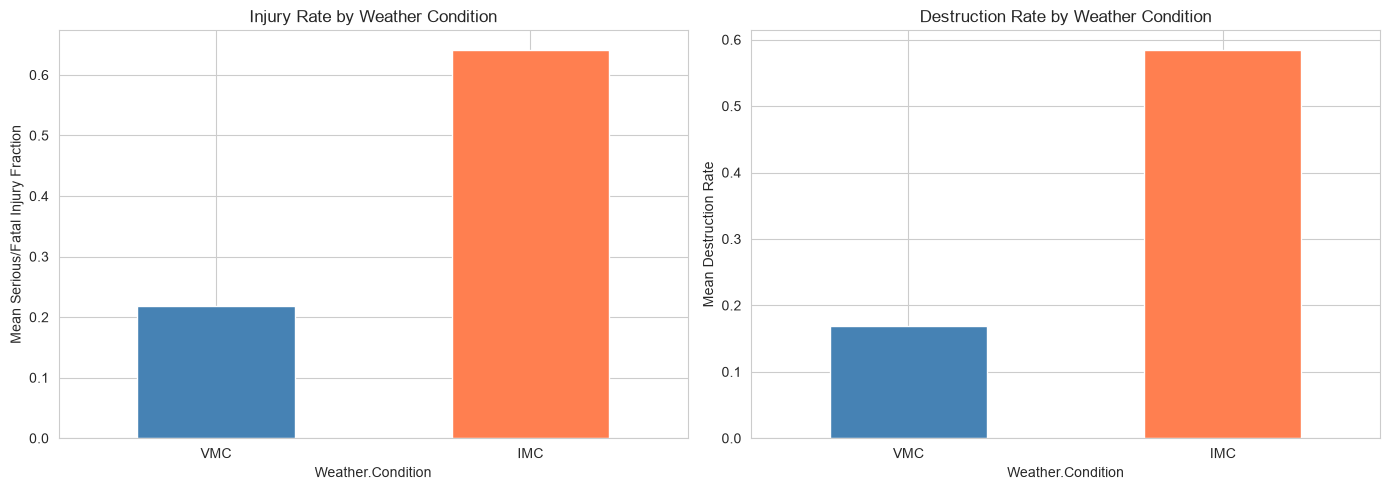

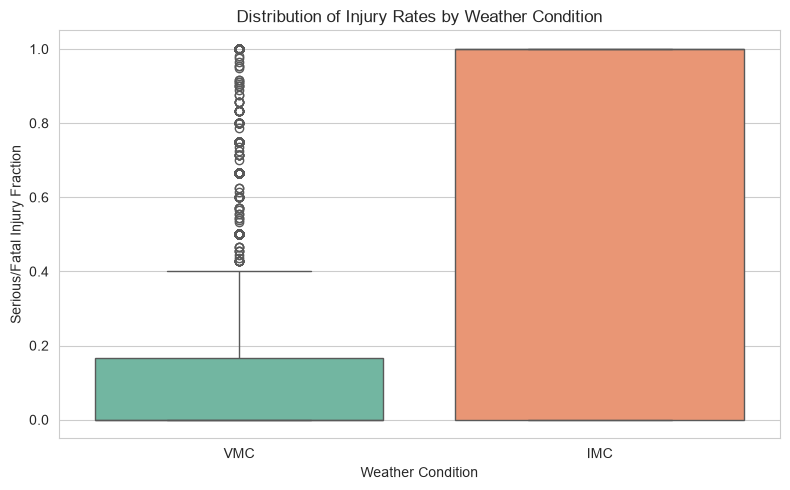

In [11]:
# ============================================================
# Factor 1: Weather Condition
# ============================================================
weather_stats = df.groupby('Weather.Condition').agg(
    mean_injury=('Serious.Fatal.Fraction', 'mean'),
    mean_destroyed=('Destroyed', 'mean'),
    count=('Serious.Fatal.Fraction', 'count')
).sort_values('mean_injury')

print("=== Weather Condition Summary ===")
display(weather_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

weather_stats['mean_injury'].plot(kind='bar', ax=axes[0], color=['steelblue', 'coral'])
axes[0].set_ylabel('Mean Serious/Fatal Injury Fraction')
axes[0].set_title('Injury Rate by Weather Condition')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

weather_stats['mean_destroyed'].plot(kind='bar', ax=axes[1], color=['steelblue', 'coral'])
axes[1].set_ylabel('Mean Destruction Rate')
axes[1].set_title('Destruction Rate by Weather Condition')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.savefig('images/weather_condition_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# Box plot for injury distribution by weather
df_weather = df.dropna(subset=['Weather.Condition'])
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_weather, x='Weather.Condition', y='Serious.Fatal.Fraction',
            hue='Weather.Condition', palette='Set2', legend=False)
plt.xlabel('Weather Condition')
plt.ylabel('Serious/Fatal Injury Fraction')
plt.title('Distribution of Injury Rates by Weather Condition')
plt.tight_layout()
plt.show()

#### Factor 1 Discussion — Weather Condition

The summary table shows a stark contrast between the two weather categories:

| Condition | Mean Injury Fraction | Mean Destruction Rate | Accidents |
|-----------|---------------------:|----------------------:|----------:|
| **VMC**   | 0.22                 | 0.17                  | 54,623    |
| **IMC**   | 0.64                 | 0.58                  | 4,987     |

IMC accidents have a mean serious/fatal injury fraction roughly **three times higher** than VMC (0.64 vs. 0.22, n = 4,987 and 54,623 respectively). The destruction rate follows the same pattern (0.58 vs. 0.17). Both groups have large sample sizes, making this comparison robust.

The box plot shows that in VMC, the median injury fraction sits near 0 with a large number of zero-injury incidents. In IMC, the distribution shifts upward — the upper quartile reaches well into severe territory. The difference is concentrated in the right tail: IMC accidents are far more likely to result in catastrophic outcomes.

**Takeaway for the client:** Weather condition is one of the strongest predictors of accident severity. Aircraft or routes operating frequently in IMC-prone environments may justify higher risk premiums in the insurer's portfolio.

#### Factor 2: Broad Phase of Flight

=== Phase of Flight Summary ===


,mean_injury,mean_destroyed,count
Broad.phase.of.flight,,,
Maneuvering,0.517365,0.463686,4968
Climb,0.390114,0.415030,1581
Approach,0.343296,0.296078,4834
Cruise,0.339586,0.341526,7635
Descent,0.307094,0.322654,1441
Go-Around,0.300178,0.290240,1174
Takeoff,0.225032,0.219312,9240
Standing,0.129146,0.121157,705
Landing,0.038368,0.043286,12341


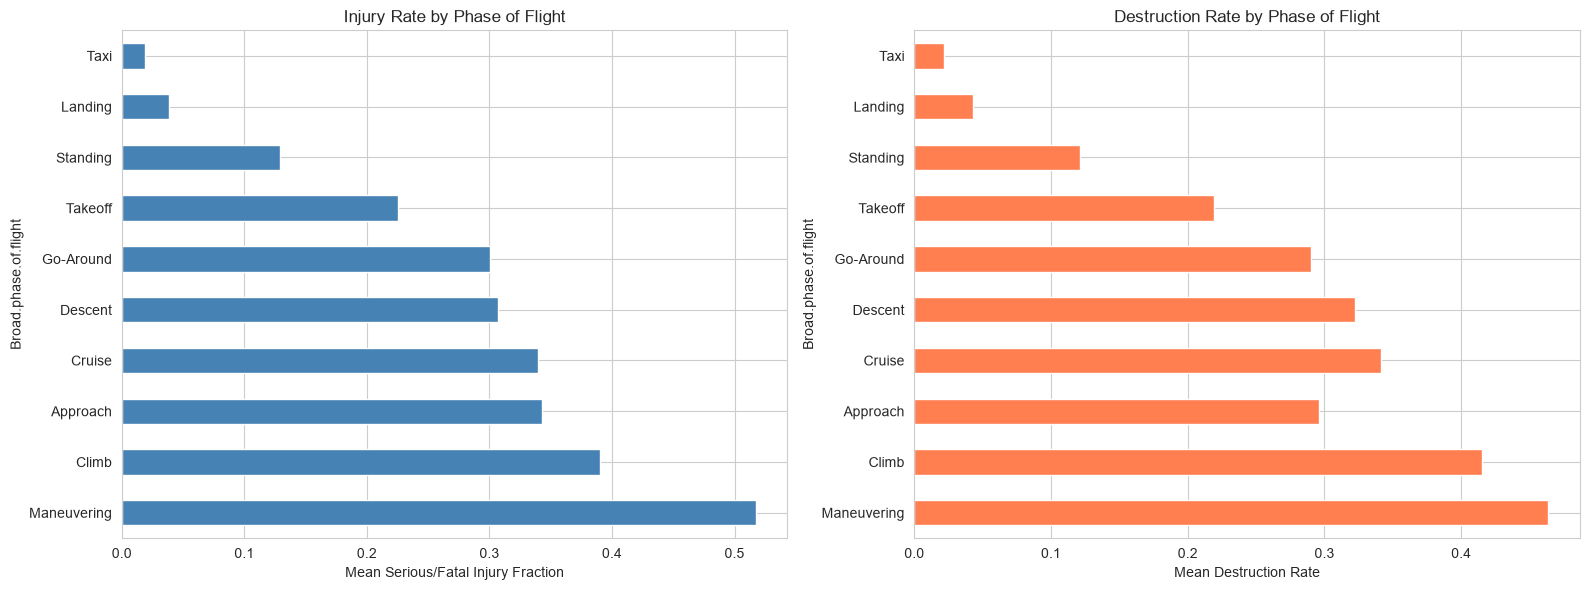

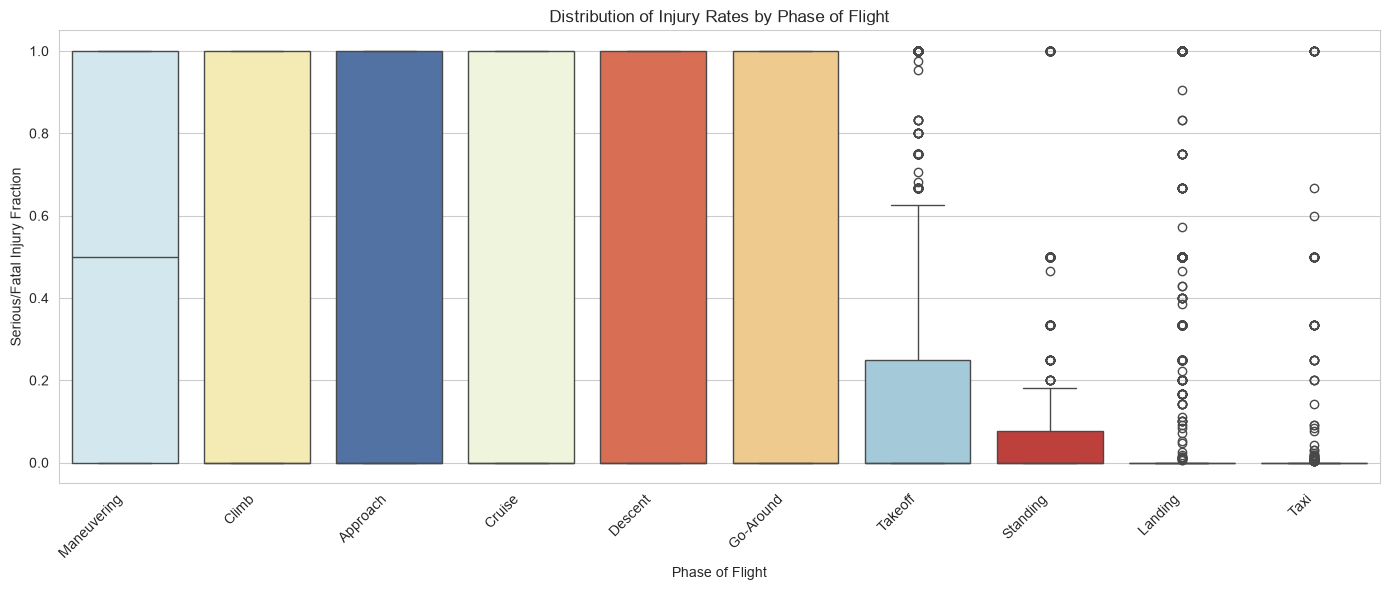

In [12]:
# ============================================================
# Factor 2: Broad Phase of Flight
# ============================================================

# Guard: check the column survived the cleaning notebook's column-removal step
if 'Broad.phase.of.flight' not in df.columns:
    print("WARNING: 'Broad.phase.of.flight' was dropped during cleaning (too many NaNs).")
    print("Falling back to 'Engine.Type' as the second factor.")
    FACTOR2_COL = 'Engine.Type'
    FACTOR2_LABEL = 'Engine Type'
else:
    FACTOR2_COL = 'Broad.phase.of.flight'
    FACTOR2_LABEL = 'Phase of Flight'

phase_stats = df.groupby(FACTOR2_COL).agg(
    mean_injury=('Serious.Fatal.Fraction', 'mean'),
    mean_destroyed=('Destroyed', 'mean'),
    count=('Serious.Fatal.Fraction', 'count')
).sort_values('mean_injury', ascending=False)

# Keep groups with meaningful sample sizes (at least 50 accidents)
phase_stats = phase_stats[phase_stats['count'] >= 50]

print(f"=== {FACTOR2_LABEL} Summary ===")
display(phase_stats)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

phase_stats['mean_injury'].plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_xlabel('Mean Serious/Fatal Injury Fraction')
axes[0].set_title(f'Injury Rate by {FACTOR2_LABEL}')

phase_stats['mean_destroyed'].plot(kind='barh', ax=axes[1], color='coral')
axes[1].set_xlabel('Mean Destruction Rate')
axes[1].set_title(f'Destruction Rate by {FACTOR2_LABEL}')

plt.tight_layout()
plt.savefig('images/phase_of_flight_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# Box plot
df_phase = df.dropna(subset=[FACTOR2_COL])
df_phase = df_phase[df_phase[FACTOR2_COL].isin(phase_stats.index)]

plt.figure(figsize=(14, 6))
order = phase_stats.index.tolist()
sns.boxplot(data=df_phase, x=FACTOR2_COL, y='Serious.Fatal.Fraction',
            hue=FACTOR2_COL, order=order, palette='RdYlBu_r', legend=False)
plt.xticks(rotation=45, ha='right')
plt.xlabel(FACTOR2_LABEL)
plt.ylabel('Serious/Fatal Injury Fraction')
plt.title(f'Distribution of Injury Rates by {FACTOR2_LABEL}')
plt.tight_layout()
plt.show()

#### Factor 2 Discussion — Phase of Flight

The summary table (phases with ≥50 accidents) reveals a clear gradient:

| Phase        | Mean Injury Fraction | Mean Destruction Rate | Accidents |
|--------------|---------------------:|----------------------:|----------:|
| Maneuvering  | 0.52                 | 0.46                  | 4,968     |
| Climb        | 0.39                 | 0.42                  | 1,581     |
| Approach     | 0.34                 | 0.30                  | 4,834     |
| Cruise       | 0.34                 | 0.34                  | 7,635     |
| Descent      | 0.31                 | 0.32                  | 1,441     |
| Go-Around    | 0.30                 | 0.29                  | 1,174     |
| Takeoff      | 0.23                 | 0.22                  | 9,240     |
| Standing     | 0.13                 | 0.12                  | 705       |
| Landing      | 0.04                 | 0.04                  | 12,341    |
| Taxi         | 0.02                 | 0.02                  | 1,616     |

**Maneuvering** is the most dangerous phase (0.52 mean injury fraction, n=4,968), consistent with stall/spin scenarios during turns and low-altitude maneuvers. **Cruise** and **Approach** follow, both around 0.34 — cruise-phase accidents often involve uncontrolled descents at speed, while approach accidents combine proximity to terrain with decreasing speed margins.

At the safe end, **Landing** (0.04, n=12,341) and **Taxi** (0.02, n=1,616) have very low injury and destruction rates, as expected given the low speeds and altitudes involved. Landing is also the most common phase for accidents overall (12,341 events), but the vast majority are minor.

**Takeaway for the client:** The phase of flight at the time of an accident is a strong predictor of outcome severity. Maneuvering accidents are ~25× more severe than landing accidents on average. This suggests that operational restrictions on unnecessary maneuvering, combined with well-planned approaches, can meaningfully reduce risk — information that may inform underwriting guidelines.